In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from mlxtend.frequent_patterns import apriori, association_rules

In [2]:
wine = load_wine()

df = pd.DataFrame(wine.data, columns=wine.feature_names)
df['Target'] = wine.target

print("Dataset Preview:")
print(df.head())

print("\nDataset Shape:", df.shape)

Dataset Preview:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  Tar

In [3]:
df.dropna(inplace=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.drop('Target', axis=1))

/tmp/ipykernel_41685/2197443418.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


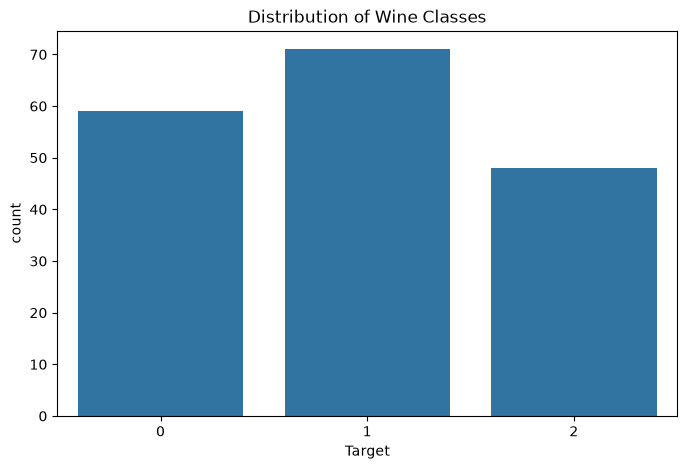

In [4]:
plt.figure(figsize=(8, 5))
sns.countplot(x='Target', data=df)
plt.title("Distribution of Wine Classes")
plt.show()

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print("\nCluster Distribution:")
print(df['Cluster'].value_counts())

# 5. Random Forest Classification
X = df.drop(['Target', 'Cluster'], axis=1)
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\nClassification Accuracy:",
      accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Cluster Distribution:
Cluster
0    65
2    62
1    51
Name: count, dtype: int64

Classification Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



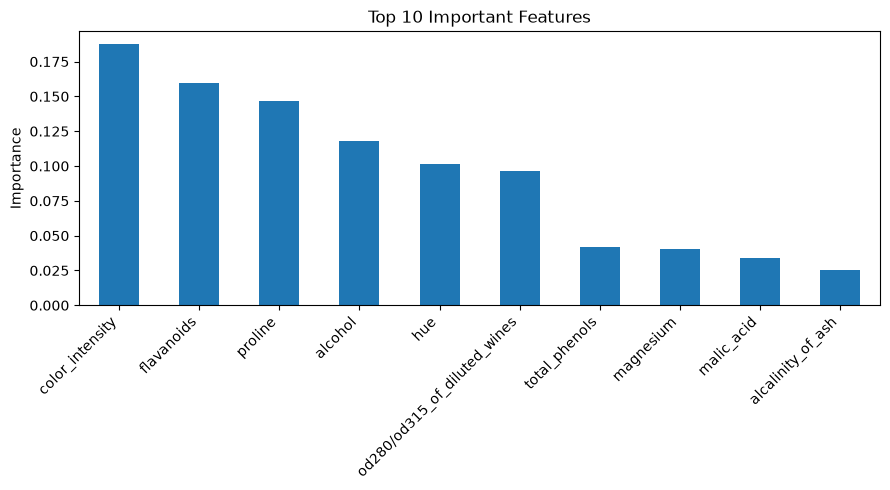

In [6]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
importance.plot(kind='bar')
plt.title("Top 10 Important Features")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()



Top Association Rules:
                                            antecedents  \
2203  frozenset({flavanoids_High, alcohol_High, proa...   
2199  frozenset({total_phenols_High, alcohol_High, p...   
2205  frozenset({flavanoids_High, color_intensity_Hi...   
2204  frozenset({total_phenols_High, color_intensity...   
2640  frozenset({flavanoids_High, color_intensity_Hi...   
2634  frozenset({total_phenols_High, proanthocyanins...   
2639  frozenset({total_phenols_High, color_intensity...   
2638  frozenset({flavanoids_High, proanthocyanins_Hi...   
2201  frozenset({flavanoids_High, proanthocyanins_Hi...   
2232  frozenset({total_phenols_High, alcohol_High, p...   

                                            consequents   support  confidence  \
2203  frozenset({total_phenols_High, color_intensity...  0.101124    0.692308   
2199  frozenset({flavanoids_High, color_intensity_Hi...  0.101124    0.692308   
2205  frozenset({total_phenols_High, alcohol_High, p...  0.101124    0.692308   
22

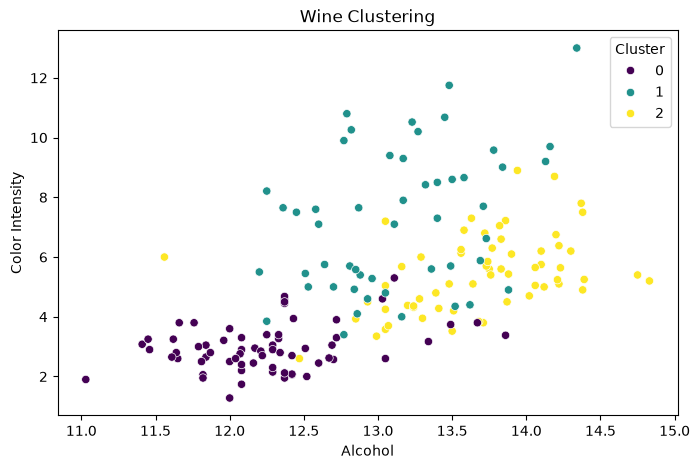

In [7]:
wine_cat = df.drop(['Target', 'Cluster'], axis=1).copy()

for col in wine_cat.columns:
    wine_cat[col] = pd.qcut(
        wine_cat[col],
        q=3,
        labels=['Low', 'Medium', 'High'],
        duplicates='drop'
    )

wine_cat = pd.get_dummies(wine_cat, dtype=bool)

frequent_items = apriori(
    wine_cat,
    min_support=0.1,
    use_colnames=True
)

rules = association_rules(
    frequent_items,
    metric="confidence",
    min_threshold=0.6
)

print("\nTop Association Rules:")
if not rules.empty:
    print(
        rules[['antecedents', 'consequents',
               'support', 'confidence', 'lift']]
        .sort_values('lift', ascending=False)
        .head(10)
    )
else:
    print("No association rules found.")

# 8. Clustering Visualization
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=df['alcohol'],
    y=df['color_intensity'],
    hue=df['Cluster'],
    palette='viridis'
)

plt.title("Wine Clustering")
plt.xlabel("Alcohol")
plt.ylabel("Color Intensity")
plt.show()